## 4.1 Business Understanding

The objective is to identify groups of customers with similar booking behaviours.

Customer segmentation helps hotel management:

- Develop targeted marketing campaigns.
- Improve loyalty programs.
- Personalize customer experiences.
- Increase revenue and customer satisfaction.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN

from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
df = pd.read_csv("hotel_bookings_cleaned 1.csv")

In [ ]:
#Feature Selection
X = df[['lead_time','total_guests','total_nights','adr','market_segment','hotel','meal']]

In [ ]:
#Identify Variables
categorical_features = ['market_segment','hotel','meal']
numerical_features = ['lead_time','total_guests','total_nights','adr']

In [ ]:
#Encoding and Scaling
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ],
    remainder='drop'
)

X_processed = preprocessor.fit_transform(X)

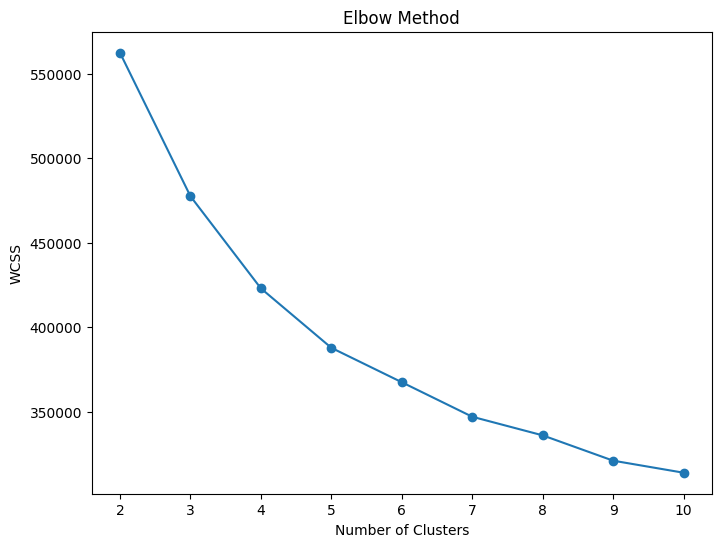

In [ ]:
#Elbow Method
wcss = []

for i in range(2,11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42
    )

    kmeans.fit(X_processed)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,6))

plt.plot(range(2,11), wcss, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.title("Elbow Method")

plt.show()

##Model 1 - K-Means

In [ ]:
#K-Means Clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(X_processed)
#Cluster lables
df['KMeans_Cluster'] = kmeans_labels

In [ ]:
#Evaluate K-Means
#Silhouette Score
silhouette_kmeans = silhouette_score(X_processed, kmeans_labels)
print("Silhouette Score:", silhouette_kmeans)

Silhouette Score: 0.2083357759713391


In [ ]:
#Davies-Bouldin Index
db_kmeans = davies_bouldin_score(X_processed, kmeans_labels)
print("Davies-Bouldin Index:", db_kmeans)

Davies-Bouldin Index: 1.4769868282748753


##Model 2 - Agglomerative Clustering

In [ ]:
# Use a sample for memory-heavy clustering models

X_cluster_sample = pd.DataFrame(X_processed).sample(
    n=5000,
    random_state=42
)

print(X_cluster_sample.shape)

(5000, 19)


In [ ]:
agg = AgglomerativeClustering(
    n_clusters=3
)
agg_labels = agg.fit_predict(X_cluster_sample)
silhouette_agg = silhouette_score(
    X_cluster_sample,
    agg_labels
)
dbi_agg = davies_bouldin_score(
    X_cluster_sample,
    agg_labels
)
print("Silhouette Score:", silhouette_agg)
print("Davies-Bouldin Index:", dbi_agg)

Silhouette Score: 0.18379866290156402
Davies-Bouldin Index: 1.957393601944838


In [ ]:
#Evaluate Agglomerative Clustering - Silhouette Score
silhouette_agg = silhouette_score(
    X_cluster_sample,
    agg_labels
)

print("Silhouette Score:", silhouette_agg)

Silhouette Score: 0.18379866290156402


In [ ]:
#Evaluate Agglomerative Clustering - Davies-Bouldin Index
davies_bouldin_agg = davies_bouldin_score(
    X_cluster_sample,
    agg_labels
)

print("Davies-Bouldin Index:", davies_bouldin_agg)

Davies-Bouldin Index: 1.957393601944838


##Model 3 - DBSCAN

In [ ]:
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_cluster_sample)
mask = dbscan_labels != -1

silhouette_dbscan = silhouette_score(
    X_cluster_sample[mask],
    dbscan_labels[mask]
)

dbi_dbscan = davies_bouldin_score(
    X_cluster_sample[mask],
    dbscan_labels[mask]
)

print("Silhouette Score:", silhouette_dbscan)
print("Davies-Bouldin Index:", dbi_dbscan)

Silhouette Score: 0.23677178423385228
Davies-Bouldin Index: 0.8996547655256742


In [ ]:
#Create a Comparison Table
results = pd.DataFrame({
    "Model": [
        "K-Means",
        "Agglomerative Clustering",
        "DBSCAN"
    ],

    "Silhouette Score": [
        silhouette_kmeans,
        silhouette_agg,
        silhouette_dbscan
    ],

    "Davies-Bouldin Index": [
        db_kmeans,
        davies_bouldin_agg,
        dbi_dbscan
    ]
})

print(results)

                      Model  Silhouette Score  Davies-Bouldin Index
0                   K-Means          0.208336              1.476987
1  Agglomerative Clustering          0.183799              1.957394
2                    DBSCAN          0.236772              0.899655


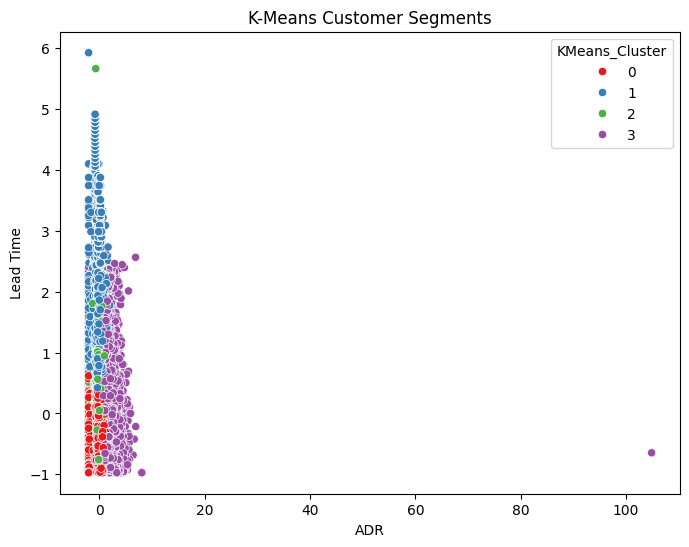

In [ ]:
#Cluster Visualization
plt.figure(figsize=(8,6))

sns.scatterplot(
    x=df['adr'],
    y=df['lead_time'],
    hue=df['KMeans_Cluster'],
    palette='Set1'
)

plt.xlabel("ADR")
plt.ylabel("Lead Time")
plt.title("K-Means Customer Segments")

plt.show()

In [ ]:
#Cluster Interpretation
cluster_summary = df.groupby('KMeans_Cluster')[
[
'total_guests',
'total_nights',
'lead_time',
'adr'
]
].mean()

print(cluster_summary)

                total_guests  total_nights  lead_time       adr
KMeans_Cluster                                                 
0                  -0.338082     -0.363742  -0.536133 -0.295895
1                  -0.104716     -0.216577   1.541215 -0.261367
2                   0.006284      1.947692   0.326201 -0.242071
3                   1.220203      0.064750  -0.264254  1.438942


## Evaluation and Reporting

Three clustering algorithms were implemented:

1. K-Means
2. Agglomerative Clustering
3. DBSCAN

The Elbow Method suggested four clusters as the optimal number of clusters for K-Means and Agglomerative Clustering.

Model performance was evaluated using Silhouette Score and Davies-Bouldin Index.

DBSCAN achieved the highest Silhouette Score (0.2368) and the lowest Davies-Bouldin Index (0.8997), indicating superior clustering performance. Therefore, DBSCAN was selected as the most effective clustering model for customer segmentation.

## Business Insights

Customer segmentation enables hotel management to identify groups of customers with similar booking behaviours.

These segments can support:

- Targeted marketing campaigns.
- Personalized customer experiences.
- Improved loyalty programs.
- Revenue optimization.
- Better customer relationship management.

The clustering results provide valuable insights for strategic decision-making.

In [ ]:
print(results)

                      Model  Silhouette Score  Davies-Bouldin Index
0                   K-Means          0.208336              1.476987
1  Agglomerative Clustering          0.183799              1.957394
2                    DBSCAN          0.236772              0.899655
